# 🏆 Competencia Selección del Mejor Modelo — Predicción de `Sales`

**Equipo:** Isabella Ramirez Santamaria y Juan Felipe Pacheco

**Resumen de la estrategia**
1. EDA que revela la estructura real de los datos (relaciones no lineales, techo de ventas y un efecto sutil pero decisivo de `Radio`).
2. Ablación para decidir qué variables sirven (¿importa `Influencer`?).
3. **9 modelos** con `GridSearchCV` (`cv=5`, `scoring='neg_root_mean_squared_error'`): Regresión Lineal, Polinómica (Ridge), KNN, Árbol, Random Forest, Gradient Boosting, XGBoost, LightGBM y SVR.
4. **Innovación:** un *Stacking Regressor* que combina los mejores modelos de familias distintas (lineal-polinómica, kernel, boosting, vecinos) con un meta-modelo no negativo.
5. Comparación **honesta**: los modelos se re-evalúan con validación cruzada repetida con *semillas distintas* a las usadas para ajustar hiperparámetros, para no premiar el sobreajuste a los folds de tuning.

In [ ]:
import warnings, os, random
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import KFold, RepeatedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

SEED = 42
random.seed(SEED); np.random.seed(SEED); os.environ['PYTHONHASHSEED'] = str(SEED)
sns.set_theme(style='whitegrid')
CV_TUNING = KFold(n_splits=5, shuffle=True, random_state=SEED)      # folds para GridSearchCV
SCORING = 'neg_root_mean_squared_error'

## 1. Carga y exploración

In [ ]:
df = pd.read_csv('train_df_ventas.csv')   # el archivo debe estar en la misma carpeta del notebook
print(df.shape)
display(df.head())
display(df.describe().T)
print('Nulos:\n', df.isna().sum().to_string())
print('Duplicados:', df.duplicated().sum())

(3409, 5)


,TV,Social Media,Influencer,Radio,Sales
0,25.406596,3.215455,Micro,22.242510,262.401171
1,16.843664,1.582102,Micro,22.242668,207.189311
2,24.081300,6.713942,Micro,22.604651,233.741252
3,11.503184,2.519338,Nano,21.419416,162.315614
4,8.183954,0.147169,Nano,22.201319,114.203929


,count,mean,std,min,25%,50%,75%,max
TV,3409.0,18.099800,9.674245,0.000684,10.400534,17.790135,25.647047,48.871161
Social Media,3409.0,3.335881,2.199525,0.000977,1.573397,3.057987,4.810377,13.981662
Radio,3409.0,22.091153,0.472815,21.032941,21.718454,22.056957,22.453868,23.205962
Sales,3409.0,191.550856,93.502192,31.199409,110.439374,188.667483,271.542296,362.042123


Nulos:
 TV              0
Social Media    0
Influencer      0
Radio           0
Sales           0
Duplicados: 0


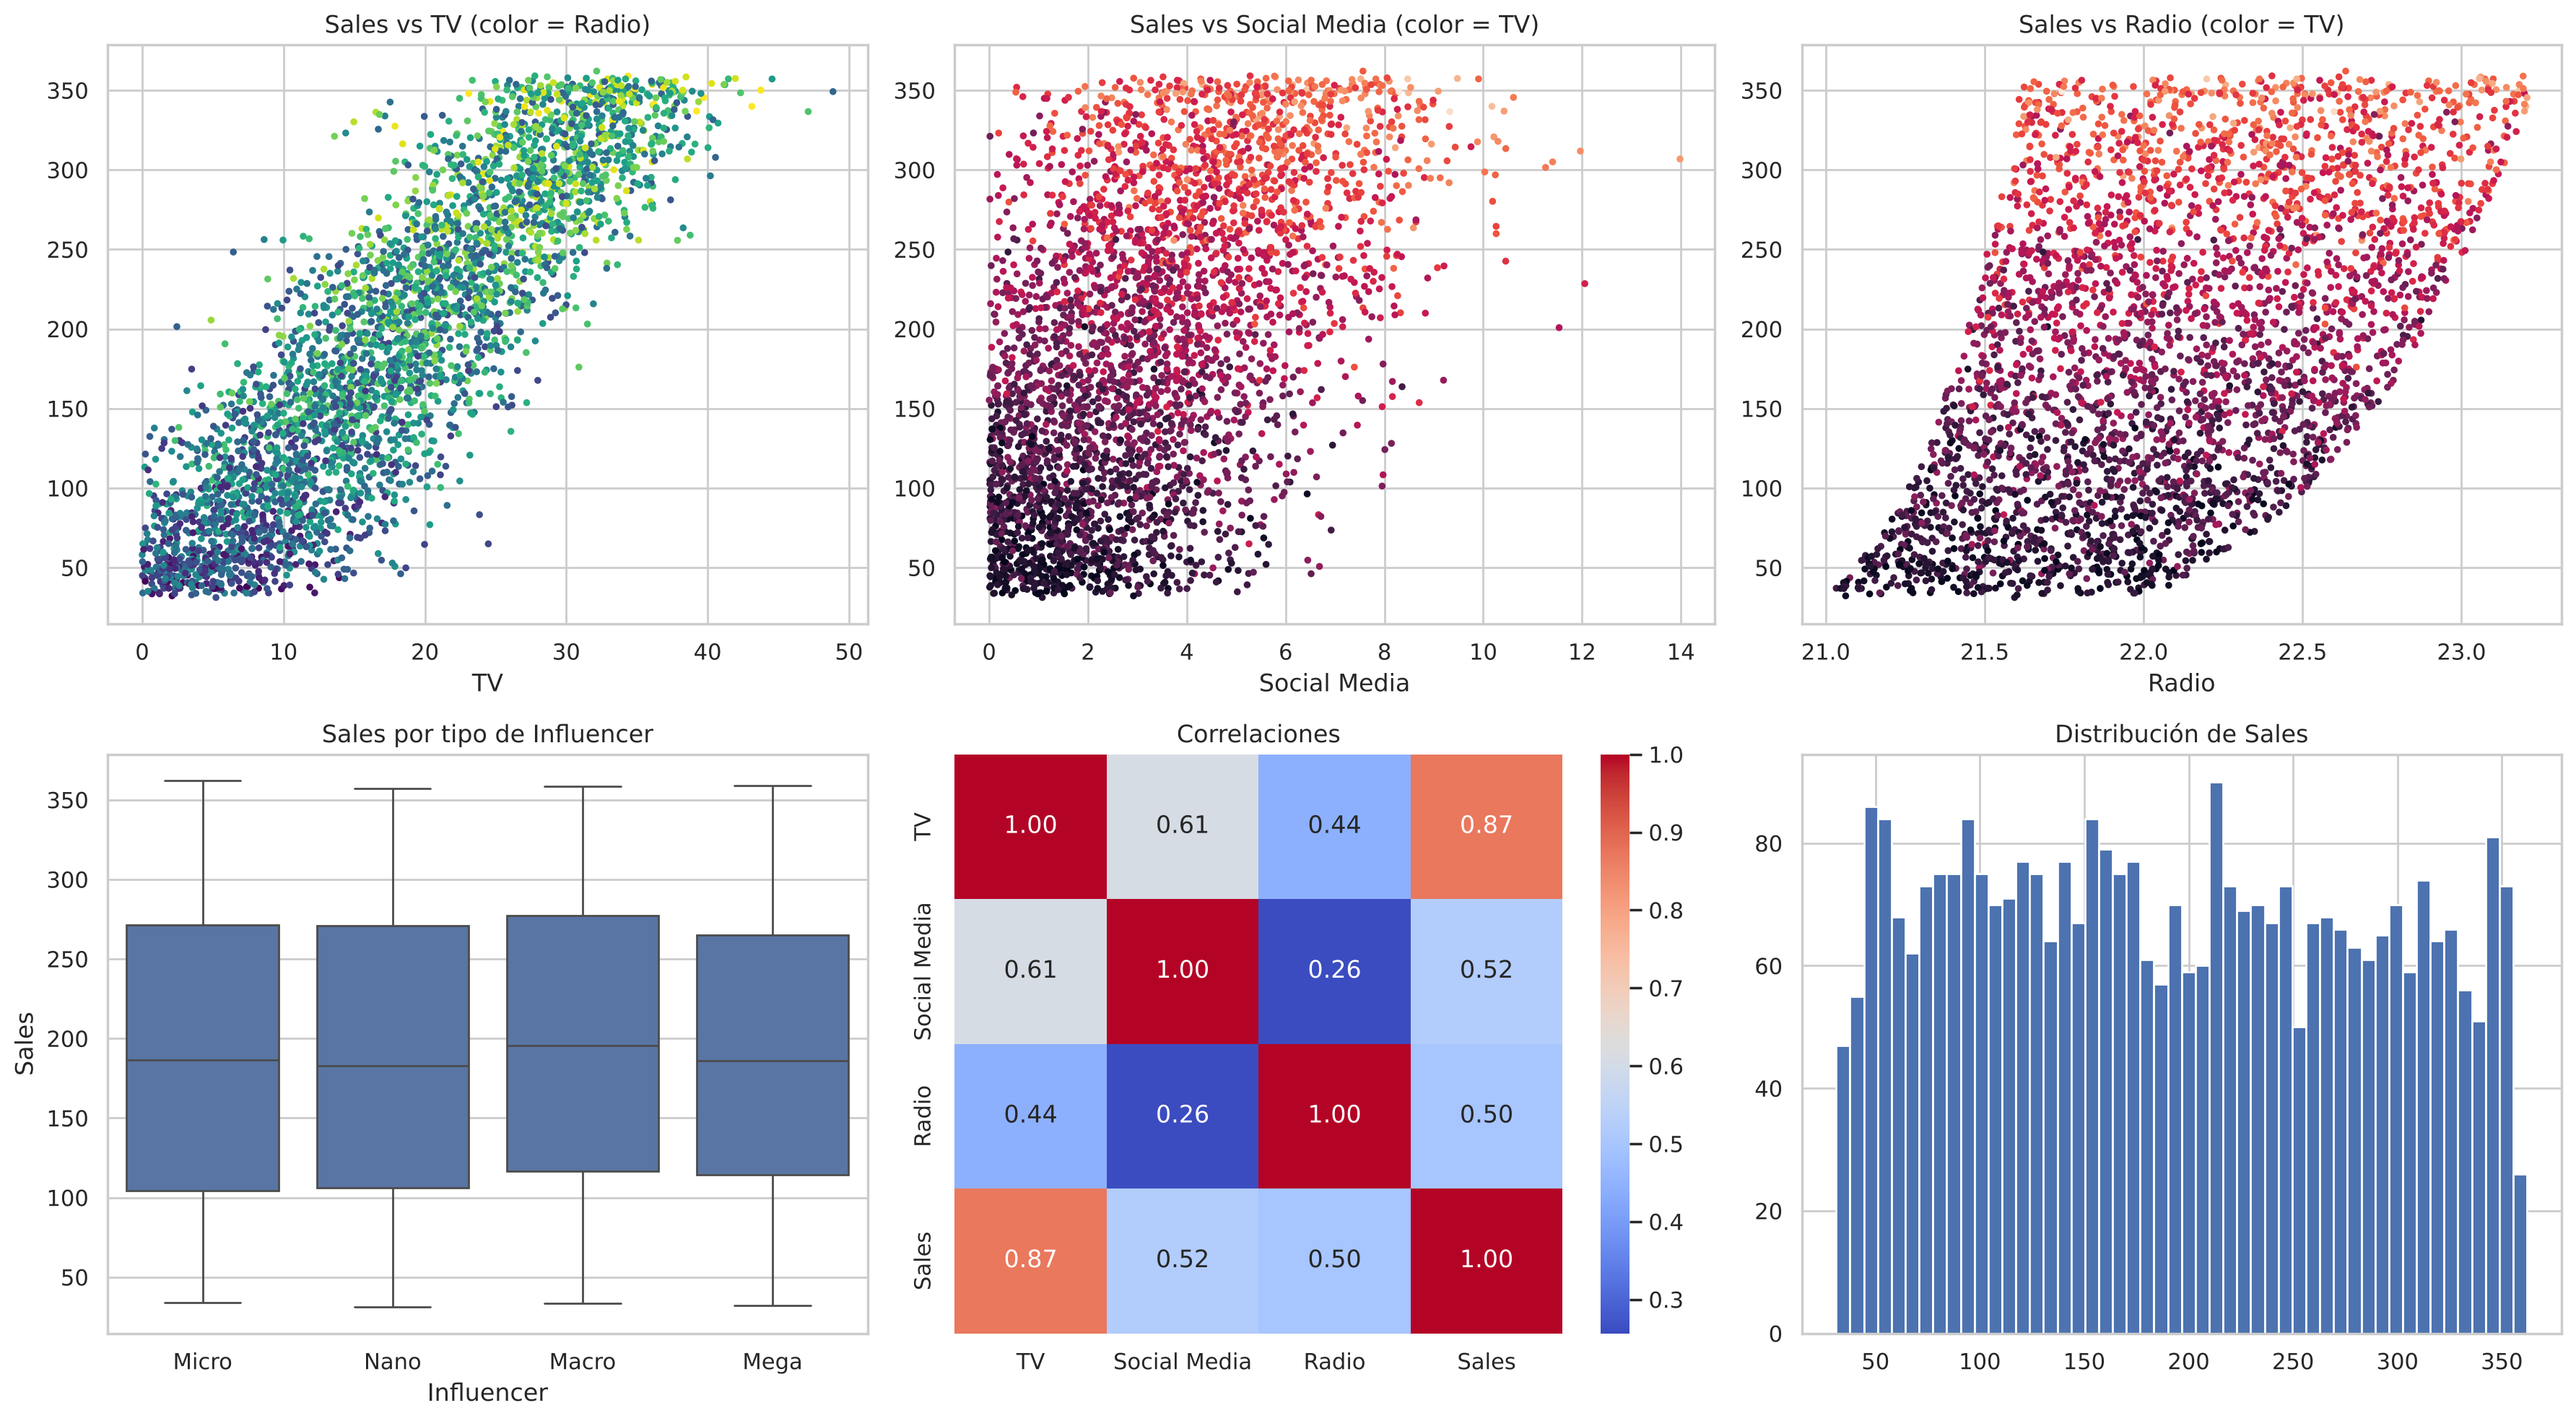

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(18, 10))
ax[0,0].scatter(df.TV, df.Sales, c=df.Radio, s=6, cmap='viridis'); ax[0,0].set(title='Sales vs TV (color = Radio)', xlabel='TV')
ax[0,1].scatter(df['Social Media'], df.Sales, c=df.TV, s=6); ax[0,1].set(title='Sales vs Social Media (color = TV)', xlabel='Social Media')
ax[0,2].scatter(df.Radio, df.Sales, c=df.TV, s=6); ax[0,2].set(title='Sales vs Radio (color = TV)', xlabel='Radio')
sns.boxplot(data=df, x='Influencer', y='Sales', ax=ax[1,0]); ax[1,0].set_title('Sales por tipo de Influencer')
sns.heatmap(df.select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax[1,1]); ax[1,1].set_title('Correlaciones')
ax[1,2].hist(df.Sales, bins=50); ax[1,2].set_title('Distribución de Sales')
plt.tight_layout(); plt.show()

**Hallazgos del EDA**
- `TV` es la variable dominante, pero la relación es **curva** (saturación) y la dispersión es **heterocedástica** (mayor en el centro del rango).
- `Radio` tiene un rango minúsculo (≈21–23), pero el gráfico *Sales vs Radio* muestra una **envolvente** muy nítida: cada nivel de Radio limita por abajo las ventas posibles, y las ventas tienen un **techo ≈ 360**. Radio, aunque parece "casi constante", aporta información real.
- `Influencer` aparenta no tener efecto (medias casi idénticas). Lo verificamos con una ablación.

## 2. Preprocesamiento y ablación de variables

In [ ]:
y = df['Sales']
X_num = df[['TV', 'Social Media', 'Radio']]
X_full = pd.get_dummies(df.drop(columns='Sales'), columns=['Influencer'], drop_first=True).astype(float)

def cv_rmse(model, X, cv=CV_TUNING):
    return -cross_val_score(model, X, y, cv=cv, scoring=SCORING, n_jobs=-1).mean()

gb_ref = lambda: GradientBoostingRegressor(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8, random_state=SEED)
abl = pd.DataFrame({
    'Lineal':            {'con Influencer': cv_rmse(LinearRegression(), X_full), 'sin Influencer': cv_rmse(LinearRegression(), X_num)},
    'Gradient Boosting': {'con Influencer': cv_rmse(gb_ref(), X_full),          'sin Influencer': cv_rmse(gb_ref(), X_num)},
}).T
display(abl.round(3))
display(pd.DataFrame({
    'TV':          [cv_rmse(gb_ref(), df[['TV']])],
    'TV+SM':       [cv_rmse(gb_ref(), df[['TV','Social Media']])],
    'TV+Radio':    [cv_rmse(gb_ref(), df[['TV','Radio']])],
    'TV+SM+Radio': [cv_rmse(gb_ref(), X_num)],
}, index=['RMSE GB']).round(3))

,con Influencer,sin Influencer
Lineal,44.535,44.528
Gradient Boosting,42.556,42.547


,TV,TV+SM,TV+Radio,TV+SM+Radio
RMSE GB,45.89,45.86,42.561,42.547


**Conclusión del preprocesamiento:** `Influencer` no mejora el RMSE (solo añade ruido), así que **se descarta**. Social Media aporta casi nada marginal una vez se conoce TV, pero Radio sí (baja el RMSE ≈3 puntos al combinarla con TV). Usamos `TV`, `Social Media` y `Radio`. No hay nulos ni duplicados y no es necesario imputar; los modelos sensibles a escala (Ridge, KNN, SVR) llevan `StandardScaler` **dentro del pipeline** para evitar fuga de datos.

In [ ]:
X = X_num.copy()   # matriz final de variables

## 3. Modelos con `GridSearchCV` (cv=5, RMSE)

In [ ]:
def tune(nombre, estimador, grid):
    gs = GridSearchCV(estimador, grid, cv=CV_TUNING, scoring=SCORING, n_jobs=-1, refit=True)
    gs.fit(X, y)
    print(f'{nombre:<18} RMSE CV = {-gs.best_score_:7.3f} | {gs.best_params_}')
    return gs

resultados = {}

resultados['Regresión Lineal'] = tune('Regresión Lineal',
    make_pipeline(StandardScaler(), LinearRegression()), {'linearregression__fit_intercept': [True]})

resultados['Regresión Polinómica'] = tune('Regresión Polinómica',
    make_pipeline(StandardScaler(), PolynomialFeatures(include_bias=False), StandardScaler(), Ridge()),
    {'polynomialfeatures__degree': [2, 3, 4, 5], 'ridge__alpha': [0.1, 1, 10, 100, 300]})

resultados['KNN'] = tune('KNN',
    make_pipeline(StandardScaler(), KNeighborsRegressor()),
    {'kneighborsregressor__n_neighbors': [20, 30, 40, 50, 60, 80],
     'kneighborsregressor__weights': ['uniform', 'distance'],
     'kneighborsregressor__p': [1, 2]})

resultados['Árbol de Decisión'] = tune('Árbol de Decisión',
    DecisionTreeRegressor(random_state=SEED),
    {'max_depth': [3, 4, 5, 6, 8], 'min_samples_leaf': [10, 20, 40, 80]})

resultados['Random Forest'] = tune('Random Forest',
    RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
    {'max_depth': [4, 6, 8, None], 'min_samples_leaf': [5, 10, 20, 40], 'max_features': [0.67, 1.0]})

resultados['Gradient Boosting'] = tune('Gradient Boosting',
    GradientBoostingRegressor(random_state=SEED),
    {'n_estimators': [200, 400], 'learning_rate': [0.01, 0.03, 0.05], 'max_depth': [2, 3],
     'subsample': [0.7, 1.0], 'min_samples_leaf': [10, 30]})

Regresión Lineal   RMSE CV =  44.528 | {'linearregression__fit_intercept': True}


Regresión Polinómica RMSE CV =  42.317 | {'polynomialfeatures__degree': 5, 'ridge__alpha': 10}


KNN                RMSE CV =  43.161 | {'kneighborsregressor__n_neighbors': 40, 'kneighborsregressor__p': 2, 'kneighborsregressor__weights': 'distance'}


Árbol de Decisión  RMSE CV =  43.971 | {'max_depth': 6, 'min_samples_leaf': 10}


Random Forest      RMSE CV =  42.821 | {'max_depth': 6, 'max_features': 0.67, 'min_samples_leaf': 5}


Gradient Boosting  RMSE CV =  42.452 | {'learning_rate': 0.03, 'max_depth': 3, 'min_samples_leaf': 10, 'n_estimators': 200, 'subsample': 0.7}


In [ ]:
resultados['XGBoost'] = tune('XGBoost',
    XGBRegressor(random_state=SEED, n_jobs=1, verbosity=0),
    {'n_estimators': [300, 600], 'learning_rate': [0.01, 0.03], 'max_depth': [2, 3, 4],
     'subsample': [0.7, 0.9], 'colsample_bytree': [0.8, 1.0], 'min_child_weight': [5, 20]})

resultados['LightGBM'] = tune('LightGBM',
    LGBMRegressor(random_state=SEED, n_jobs=1, verbose=-1),
    {'n_estimators': [300, 600], 'learning_rate': [0.01, 0.03], 'num_leaves': [4, 8, 16],
     'min_child_samples': [20, 50], 'subsample': [0.7], 'subsample_freq': [1], 'reg_lambda': [0, 10]})

resultados['SVR (kernel RBF)'] = tune('SVR (kernel RBF)',
    make_pipeline(StandardScaler(), SVR(kernel='rbf')),
    {'svr__C': [50, 100, 200, 400, 800], 'svr__gamma': [0.03, 0.05, 0.1, 0.2], 'svr__epsilon': [1, 5, 10]})

XGBoost            RMSE CV =  42.535 | {'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 600, 'subsample': 0.7}


LightGBM           RMSE CV =  42.636 | {'learning_rate': 0.01, 'min_child_samples': 20, 'n_estimators': 600, 'num_leaves': 8, 'reg_lambda': 0, 'subsample': 0.7, 'subsample_freq': 1}


SVR (kernel RBF)   RMSE CV =  42.446 | {'svr__C': 800, 'svr__epsilon': 10, 'svr__gamma': 0.1}


## 4. Innovación: Stacking de familias distintas

Los modelos de la sección 3 aprenden la misma señal de formas diferentes (polinomio suave, kernel, boosting, vecinos locales). Sus errores no están perfectamente correlacionados, así que un **meta-modelo de regresión lineal con coeficientes no negativos** (`positive=True`, equivale a un promedio ponderado aprendido) puede bajar el error. Los modelos base entran **ya afinados** y el stacking genera las predicciones del meta-modelo con validación cruzada interna (sin salida).

In [ ]:
bases = ['Regresión Polinómica', 'SVR (kernel RBF)', 'Gradient Boosting', 'XGBoost', 'LightGBM', 'KNN']
from sklearn.base import clone
stack = StackingRegressor(
    estimators=[(n.split()[0].lower() + str(i), clone(resultados[n].best_estimator_)) for i, n in enumerate(bases)],
    final_estimator=LinearRegression(positive=True),
    cv=KFold(5, shuffle=True, random_state=SEED), n_jobs=-1)
stack.fit(X, y)
print('Pesos del meta-modelo:')
for (n, _), w in zip(stack.estimators, stack.final_estimator_.coef_):
    print(f'  {n:<12} {w:6.3f}')
print('  intercepto  ', round(stack.final_estimator_.intercept_, 3))

Pesos del meta-modelo:
  regresión0    0.425
  svr1          0.197
  gradient2     0.361
  xgboost3      0.000
  lightgbm4     0.000
  knn5          0.017
  intercepto   0.204


## 5. Comparación justa de todos los modelos

`best_score_` de `GridSearchCV` es optimista (se eligió el máximo entre muchas combinaciones sobre los mismos folds). Para comparar con justicia, re-evaluamos cada modelo ya configurado con **validación cruzada repetida (5 folds × 3 repeticiones) con una semilla distinta** a la del tuning.

,Modelo,RMSE GridSearch (cv=5),RMSE CV repetida,Desv. folds
0,Stacking (innovación),NaN,42.259,1.122
1,Regresión Polinómica,42.317,42.380,1.054
2,XGBoost,42.535,42.497,1.179
3,SVR (kernel RBF),42.446,42.511,1.189
4,Gradient Boosting,42.452,42.518,1.189
5,LightGBM,42.636,42.640,1.172
6,Random Forest,42.821,42.688,1.174
7,KNN,43.161,43.250,1.132
8,Árbol de Decisión,43.971,44.033,1.220
9,Regresión Lineal,44.528,44.557,0.843


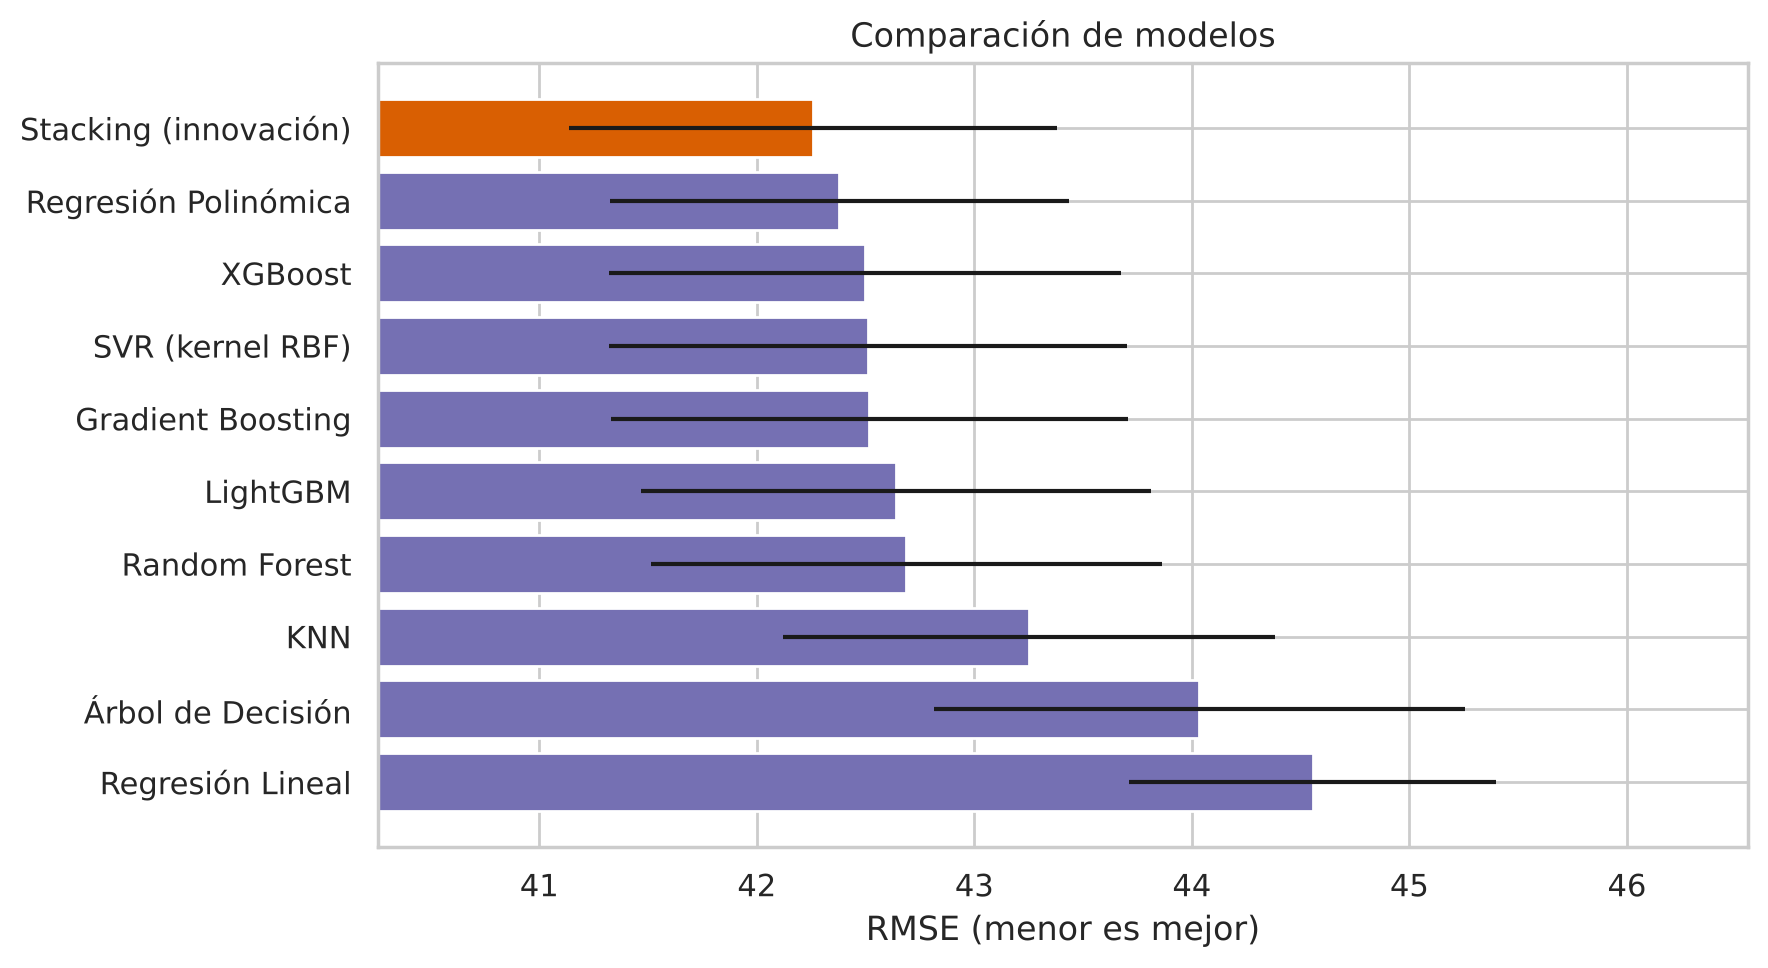

In [ ]:
cv_eval = RepeatedKFold(n_splits=5, n_repeats=3, random_state=2026)
filas = []
for nombre, gs in resultados.items():
    sc = -cross_val_score(clone(gs.best_estimator_), X, y, cv=cv_eval, scoring=SCORING, n_jobs=-1)
    filas.append((nombre, -gs.best_score_, sc.mean(), sc.std()))
sc = -cross_val_score(clone(stack), X, y, cv=cv_eval, scoring=SCORING)
filas.append(('Stacking (innovación)', np.nan, sc.mean(), sc.std()))

tabla = (pd.DataFrame(filas, columns=['Modelo', 'RMSE GridSearch (cv=5)', 'RMSE CV repetida', 'Desv. folds'])
           .sort_values('RMSE CV repetida').reset_index(drop=True))
display(tabla.round(3))

plt.figure(figsize=(9, 5))
t = tabla.sort_values('RMSE CV repetida', ascending=False)
plt.barh(t['Modelo'], t['RMSE CV repetida'], xerr=t['Desv. folds'], color=['#d95f02' if 'Stacking' in m else '#7570b3' for m in t['Modelo']])
plt.xlim(t['RMSE CV repetida'].min() - 2, t['RMSE CV repetida'].max() + 2)
plt.xlabel('RMSE (menor es mejor)'); plt.title('Comparación de modelos'); plt.tight_layout(); plt.show()

In [ ]:
modelos_finales = {n: gs.best_estimator_ for n, gs in resultados.items()}
modelos_finales['Stacking (innovación)'] = stack
mejor_nombre = tabla.loc[0, 'Modelo']
mejor_modelo = modelos_finales[mejor_nombre]
print('Mejor modelo por RMSE de CV repetida:', mejor_nombre, '->', round(tabla.loc[0, 'RMSE CV repetida'], 3))

Mejor modelo por RMSE de CV repetida: Stacking (innovación) -> 42.259


## 6. Diagnóstico del modelo seleccionado

RMSE out-of-fold: 42.23 | MAE: 33.085 | R²: 0.796


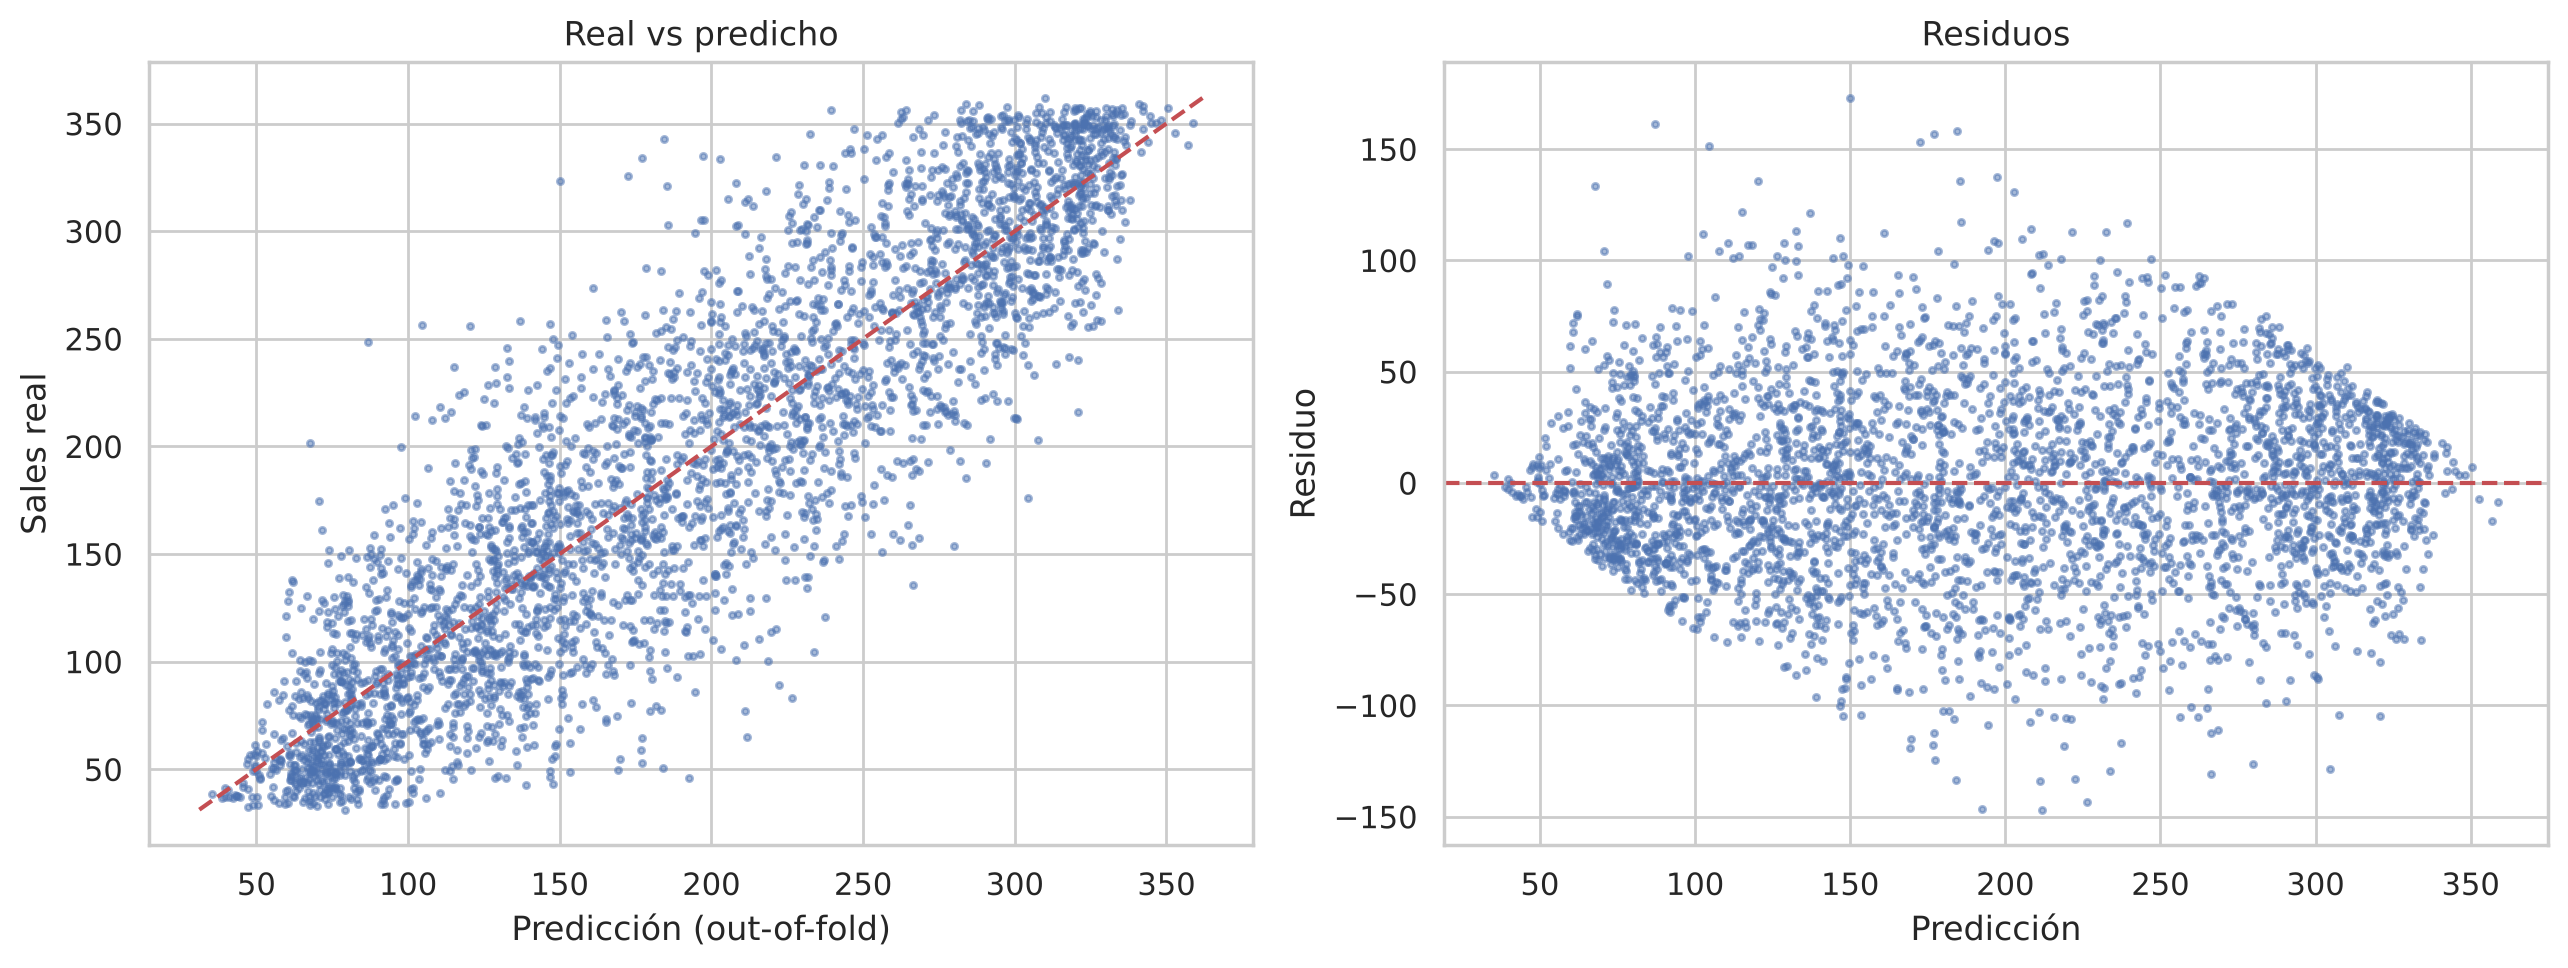

In [ ]:
from sklearn.model_selection import cross_val_predict
pred_oof = cross_val_predict(clone(mejor_modelo), X, y, cv=KFold(5, shuffle=True, random_state=7), n_jobs=-1)
res = y - pred_oof
print('RMSE out-of-fold:', round(float(np.sqrt(np.mean(res**2))), 3), '| MAE:', round(float(np.mean(np.abs(res))), 3), '| R²:', round(float(1 - res.var()/y.var()), 3))
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(pred_oof, y, s=5, alpha=.5); ax[0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--'); ax[0].set(xlabel='Predicción (out-of-fold)', ylabel='Sales real', title='Real vs predicho')
ax[1].scatter(pred_oof, res, s=5, alpha=.5); ax[1].axhline(0, color='r', ls='--'); ax[1].set(xlabel='Predicción', ylabel='Residuo', title='Residuos')
plt.tight_layout(); plt.show()

**Lectura de resultados:** los residuos conservan una dispersión grande y heterocedástica: una parte importante de la variabilidad de `Sales` no se explica con TV, Social Media y Radio (ruido irreducible). Por eso los 9 modelos quedan en un rango estrecho de RMSE y la ganancia del ensamble es pequeña pero consistente. Probamos además transformar el objetivo usando la envolvente de Radio (piso/techo por cuantiles) y no mejoró el RMSE, por lo que se descartó.

## 7. Entrenamiento final y función de predicción
El modelo seleccionado se re-entrena con **todo** el conjunto `train` (semillas fijas, resultado reproducible).

In [ ]:
modelo_final = clone(mejor_modelo).fit(X, y)

def predecir(df_nuevo: pd.DataFrame) -> np.ndarray:
    """Recibe un DataFrame con columnas TV, Social Media y Radio (Influencer, si viene, se ignora) y devuelve las ventas predichas."""
    return modelo_final.predict(df_nuevo[['TV', 'Social Media', 'Radio']])

print('Ejemplo de predicciones:', predecir(df.head()).round(1), '| reales:', df['Sales'].head().round(1).values)

Ejemplo de predicciones: [261.4 178.6 249.9 112.9 106.6] | reales: [262.4 207.2 233.7 162.3 114.2]


# ✅ **MODELO SELECCIONADO COMO EL MEJOR**

In [ ]:
from IPython.display import Markdown
Markdown(f'## 🏆 Modelo seleccionado: **{mejor_nombre}**  \nRMSE (CV repetida 5×3): **{tabla.loc[0, "RMSE CV repetida"]:.3f}**  \nHiperparámetros / configuración:  \n```\n{mejor_modelo}\n```')

## 🏆 Modelo seleccionado: **Stacking (innovación)**  
RMSE (CV repetida 5×3): **42.259**  
Hiperparámetros / configuración:  
```
StackingRegressor(cv=KFold(n_splits=5, random_state=42, shuffle=True),
                  estimators=[('regresión0',
                               Pipeline(steps=[('standardscaler-1',
                                                StandardScaler()),
                                               ('polynomialfeatures',
                                                PolynomialFeatures(degree=5,
                                                                   include_bias=False)),
                                               ('standardscaler-2',
                                                StandardScaler()),
                                               ('ridge', Ridge(alpha=10))])),
                              ('svr1',
                               Pipeline(steps=[('standardscaler',
                                                StandardScaler()),
                                               ('sv...
                              ('lightgbm4',
                               LGBMRegressor(learning_rate=0.01,
                                             n_estimators=600, n_jobs=1,
                                             num_leaves=8, random_state=42,
                                             reg_lambda=0, subsample=0.7,
                                             subsample_freq=1, verbose=-1)),
                              ('knn5',
                               Pipeline(steps=[('standardscaler',
                                                StandardScaler()),
                                               ('kneighborsregressor',
                                                KNeighborsRegressor(n_neighbors=40,
                                                                    weights='distance'))]))],
                  final_estimator=LinearRegression(positive=True), n_jobs=-1)
```